# Check a run

Set the run at the top and run all: the same report as `check_run.py`, then the figures —
position, force (felt vs robot and e_F), timing (delays, haptic period, lost controller ticks),
energy balance and, for proxy-rim, the model's Λ.

In [ ]:
RUN = "r1_zoh_0"  # a run name under DATA, or a full path
DATA = "~/data/franka/rim-delays/robot/checks"  # where the run is
XLIM = None  # e.g. (4.0, 9.0) to zoom every figure [s]

In [2]:
import sys
from pathlib import Path

HERE = Path.cwd()  # experiments/rim-delays/analysis
sys.path[:0] = [str(HERE), str(HERE.parent)]

import run_plots as P
from check_run import check
from runs import load_run

%matplotlib inline

run_dir = Path(RUN).expanduser() if Path(RUN).expanduser().is_absolute() else Path(DATA).expanduser() / RUN
run = load_run(run_dir)
assert run is not None, f"no complete run in {run_dir}"


def show(fig):
    if XLIM is not None:
        for ax in fig.axes:
            ax.set_xlim(*XLIM)
    return fig

## Report

In [3]:
from check_run import verdict

lines, warnings = check(run_dir, use_model=True, run=run)
print("\n".join(lines + verdict(warnings)))


[check_run] /home/athena/csirois/data/franka/rim-delays/robot/checks/r3_rim_0
  backend                      robot
  method                       proxy-rim  (K 1000.0 N/m, D 70.0 N·s/m)
  delay feedback / command     none / none
  script                       press
  stop reason                  run ended
  q0 [rad]                     [0.0, -0.231, -0.001, -2.701, -0.012, 2.477, 0.764]
  OSC gains (read back)        d_pos_x -1, d_pos_y -1, d_pos_z -1, damping_ratio_pos 0.7, damping_ratio_rot 0.7, k_pos_x 1500, k_pos_y 1500, k_pos_z 3500
  streams:
    haptic                       17000 rows,  1000.0 Hz,  -0.00 →  16.99 s
    robot                        15207 rows,   872.1 Hz,   0.00 →  17.44 s
    command                       8679 rows,   500.0 Hz,   0.00 →  17.36 s
    target                        8680 rows,   498.9 Hz,   0.00 →  17.40 s
    model                         8678 rows,   500.0 Hz,   0.00 →  17.36 s
  haptic loop:
    period p50 / p99 / max     1.00 / 1.01 / 1.28 ms
 

## Position
Leader, proxy (proxy methods), the target as published to the robot (after the command delay), and the robot. The table is dashed on the contact axis.

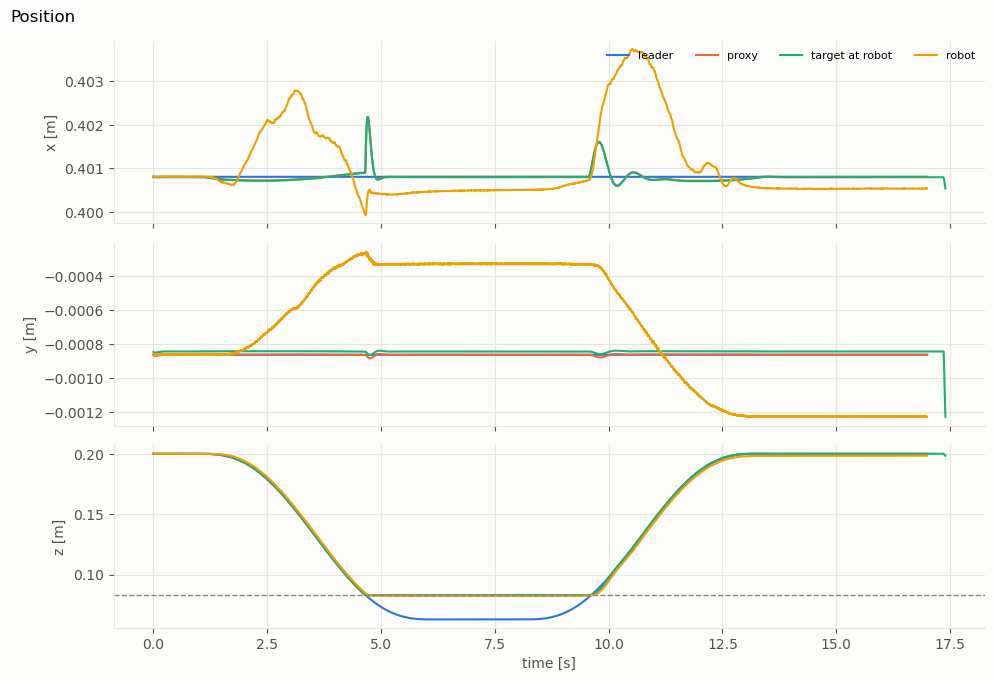

In [4]:
show(P.positions(run));

## Force
Left: the felt force and the robot's force (`-F_osc`, taken when the operator's action reached the robot): they overlap when the operator feels what the robot does. Right: their gap, the unfelt force e_F.

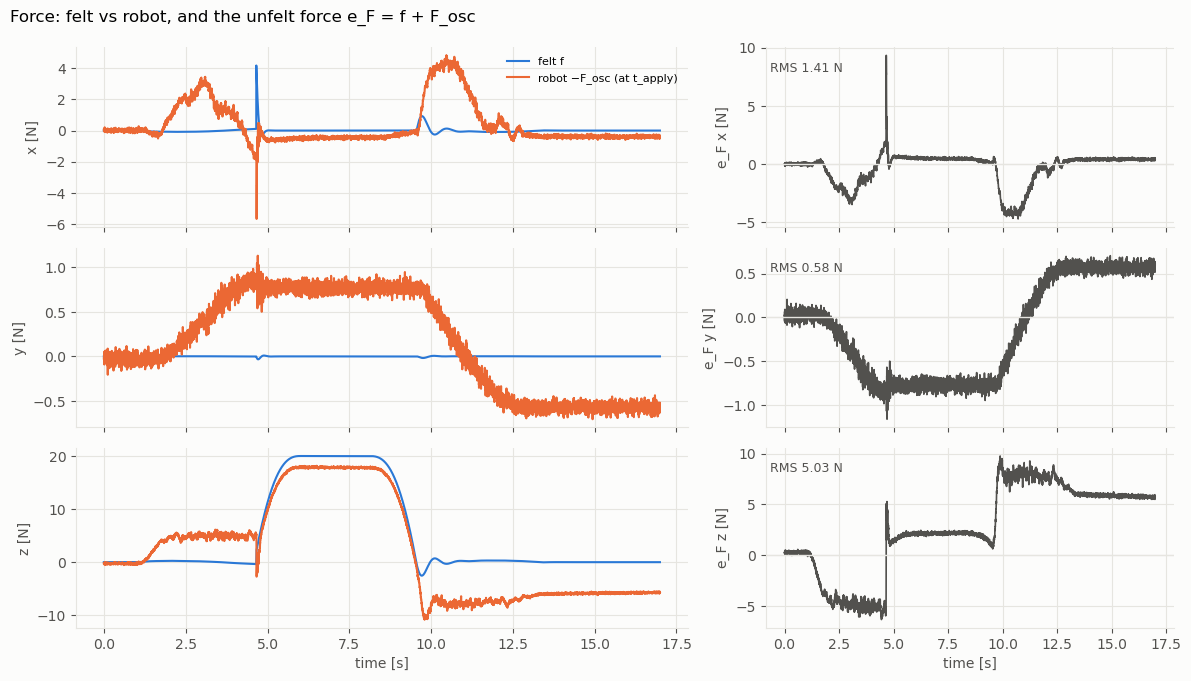

In [5]:
show(P.forces(run));

## Timing
Measured delays on both links, the haptic loop period, and the controller ticks that never reached the plant.

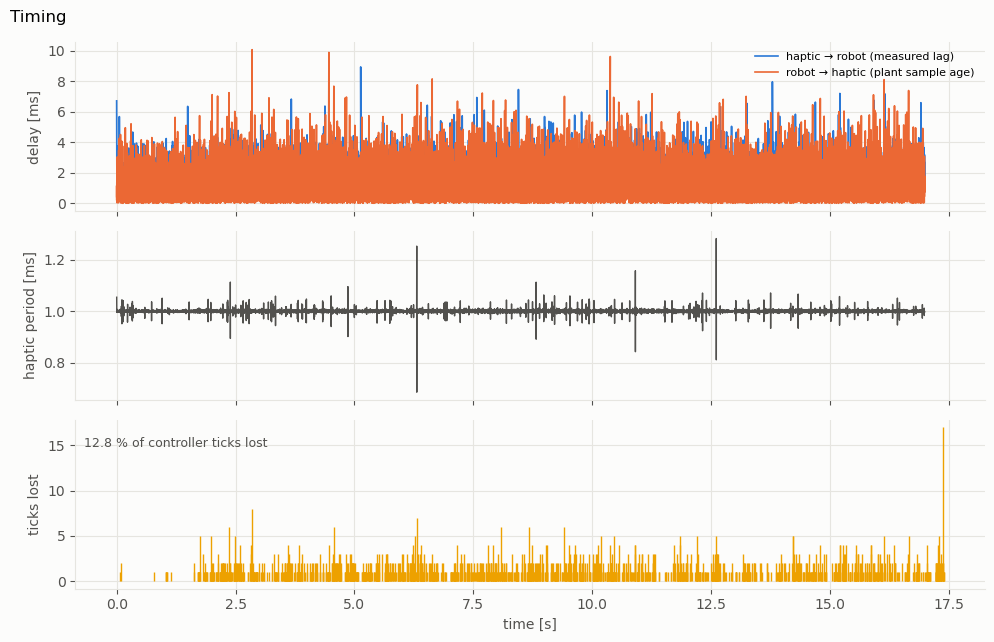

In [6]:
show(P.timing(run));

## Energy and model

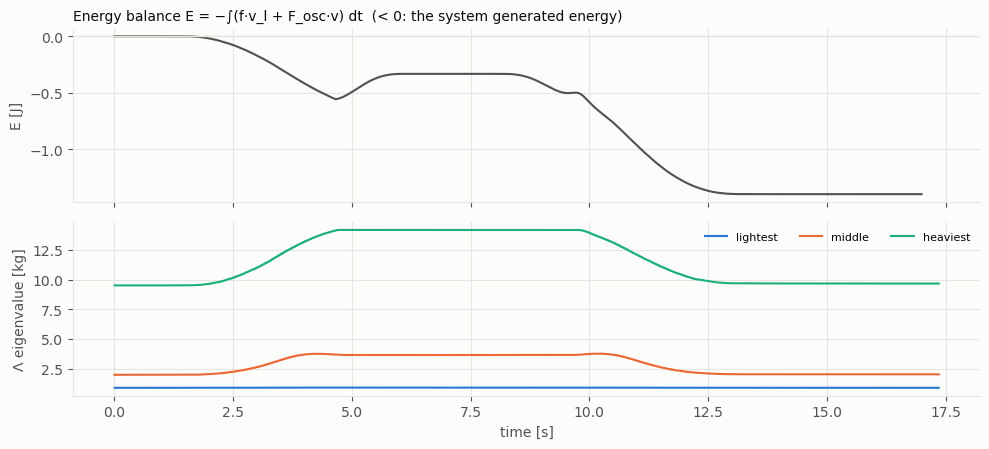

In [7]:
show(P.energy_and_model(run));